# Install Library

In [26]:
!pip -q install retina-face

# Load Dataset

In [27]:
import kagglehub

path = kagglehub.dataset_download("ajithdari/autism-spectrum-disorder-multi-modal-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'autism-spectrum-disorder-multi-modal-dataset' dataset.
Path to dataset files: /kaggle/input/autism-spectrum-disorder-multi-modal-dataset


# Verify and analyze dataset

Dataset path: /kaggle/input/autism-spectrum-disorder-multi-modal-dataset
Path exists: True

Total image files: 2926
Number of image folders: 6

Image distribution:
autistic: 1463
non_autistic: 1463


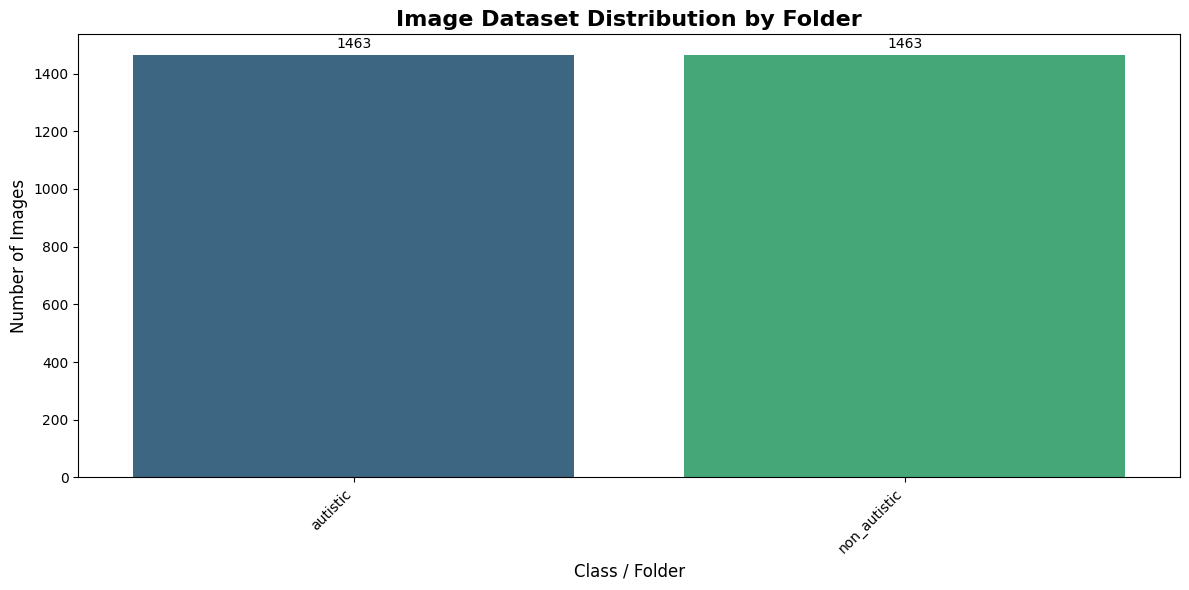

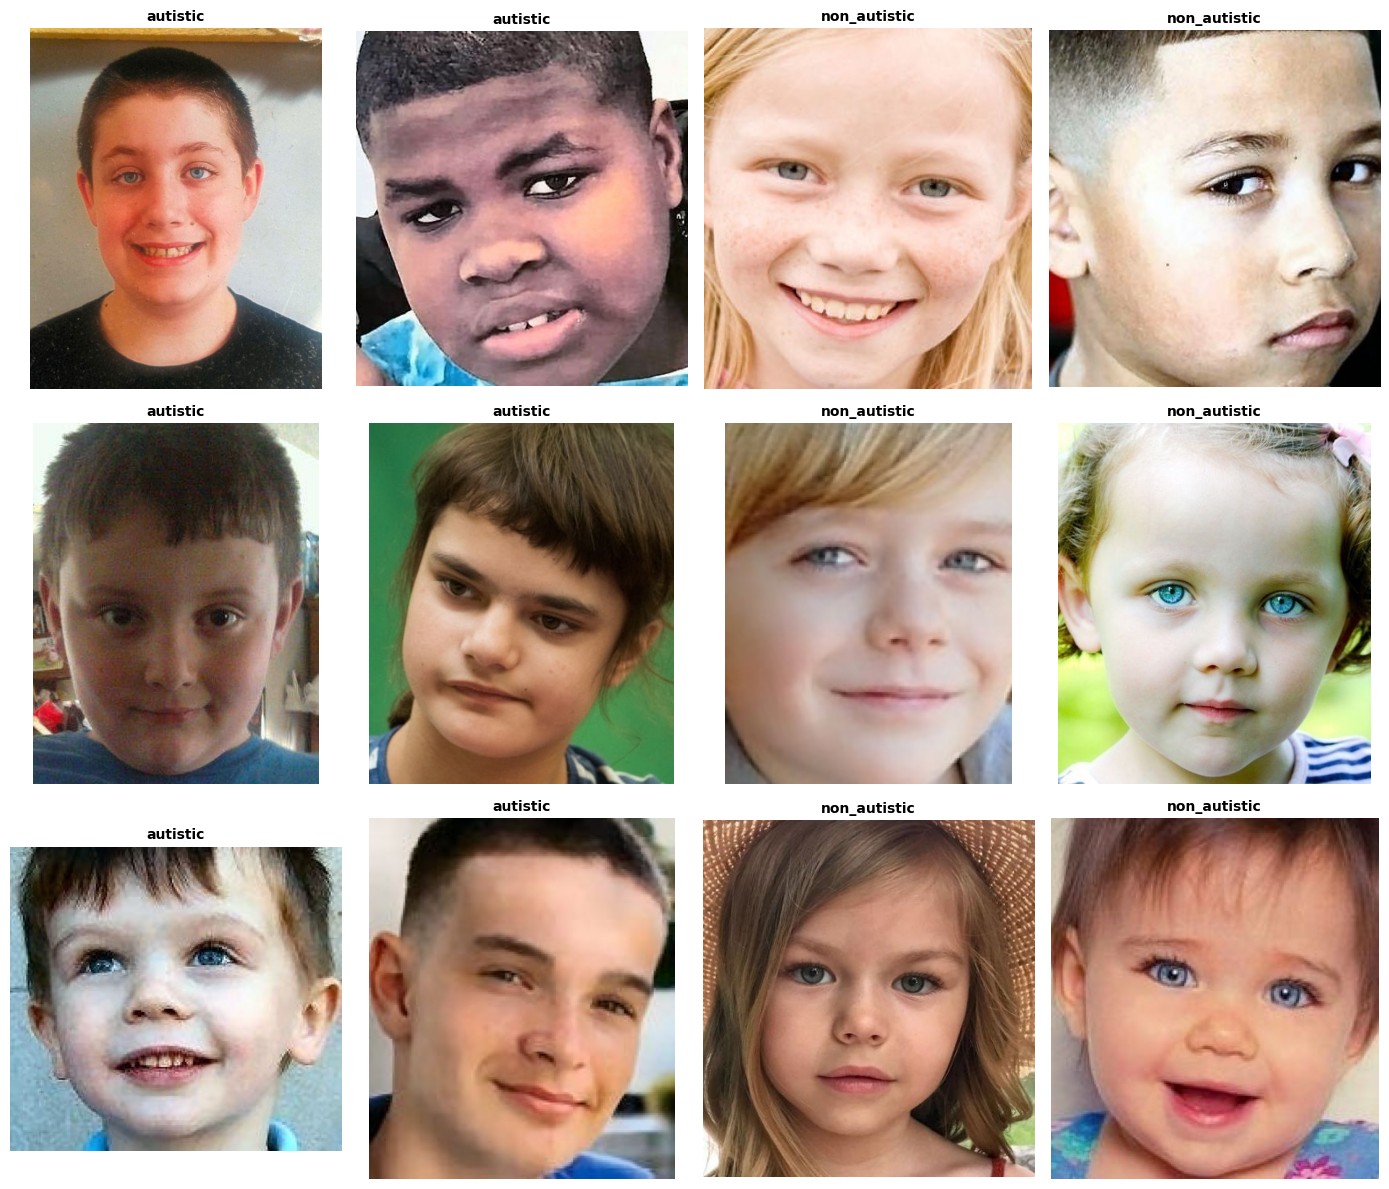

In [28]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter

print("Dataset path:", path)
print("Path exists:", os.path.exists(path))

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
class_counts = Counter()
class_folders = {}

for root, dirs, files in os.walk(path):
    images = [f for f in files if f.lower().endswith(image_extensions)]

    if images:
        class_name = os.path.basename(root)
        class_folders[root] = images
        class_counts[class_name] += len(images)

print("\nTotal image files:", sum(class_counts.values()))
print("Number of image folders:", len(class_folders))

print("\nImage distribution:")
for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

if class_counts:
    labels = list(class_counts.keys())
    counts = list(class_counts.values())

    plt.figure(figsize=(12, 6))
    ax = sns.barplot(
        x=labels,
        y=counts,
        hue=labels,
        palette="viridis",
        legend=False
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3, fontsize=10)

    plt.title("Image Dataset Distribution by Folder",
              fontsize=16, fontweight="bold")
    plt.xlabel("Class / Folder", fontsize=12)
    plt.ylabel("Number of Images", fontsize=12)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No images found. Check the dataset folder structure.")

sample_paths = []

for folder, files in class_folders.items():
    for file in files[:2]:
        sample_paths.append((os.path.join(folder, file),
                             os.path.basename(folder)))

sample_paths = sample_paths[:12]

if sample_paths:
    cols = 4
    rows = (len(sample_paths) + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for ax, (img_path, label) in zip(axes, sample_paths):
        try:
            with Image.open(img_path) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(label, fontsize=10, fontweight="bold")
            ax.axis("off")
        except Exception as e:
            ax.set_title("Unreadable image")
            ax.axis("off")

    for ax in axes[len(sample_paths):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Face Detection: RetinaFace

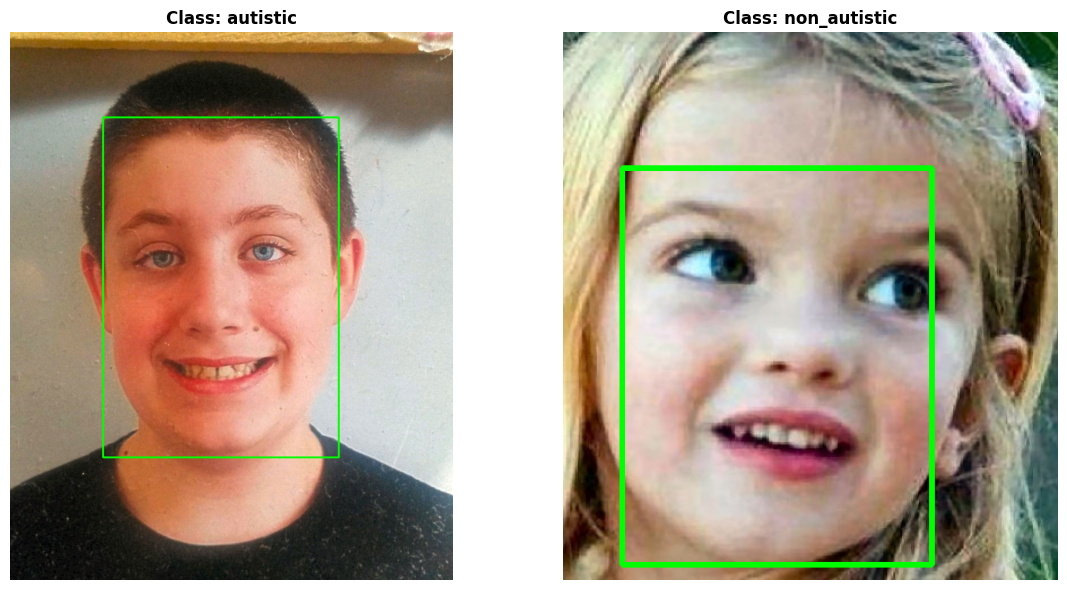

In [29]:
import os
import cv2
import matplotlib.pyplot as plt
from retinaface import RetinaFace

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
class_to_folders = {}

for root, dirs, files in os.walk(path):
    images = [f for f in files if f.lower().endswith(image_extensions)]
    if images:
        class_name = os.path.basename(root)
        if class_name not in class_to_folders:
            class_to_folders[class_name] = []
        class_to_folders[class_name].append((root, images))

class_sample_images = {}
for class_name, folders in class_to_folders.items():
    found = False
    for folder, files in folders:
        if found: break
        for file in files:
            img_path = os.path.join(folder, file)
            try:
                faces = RetinaFace.detect_faces(img_path)
                if isinstance(faces, dict) and len(faces) > 0:
                    class_sample_images[class_name] = img_path
                    found = True
                    break
            except Exception:
                continue

fig, axes = plt.subplots(1, len(class_sample_images), figsize=(12, 6))
if len(class_sample_images) == 1:
    axes = [axes]

for ax, (class_name, img_path) in zip(axes, sorted(class_sample_images.items())):
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    faces = RetinaFace.detect_faces(img_path)

    if isinstance(faces, dict) and len(faces) > 0:
        for key in faces:
            facial_area = faces[key]["facial_area"]
            x1, y1, x2, y2 = facial_area
            cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), 3)

    ax.imshow(img_rgb)
    ax.set_title(f"Class: {class_name}", fontsize=12, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Image Resizing and Pixel Normalization

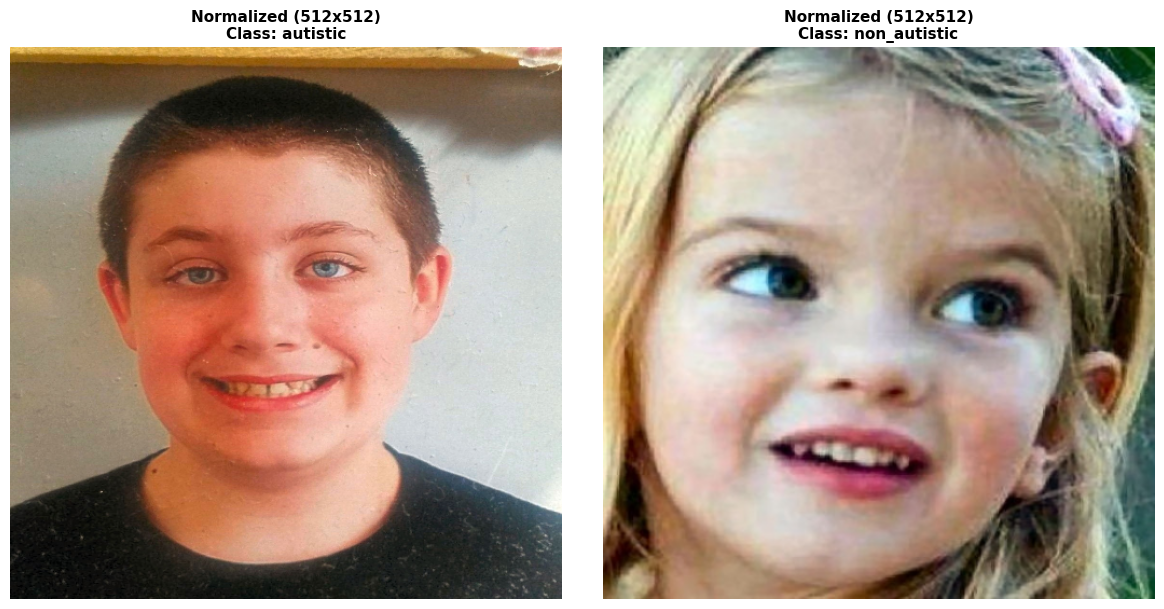

[autistic] Shape: (512, 512, 3) | Min Pixel: 0.00 | Max Pixel: 1.00
[non_autistic] Shape: (512, 512, 3) | Min Pixel: 0.00 | Max Pixel: 1.00


In [30]:
import numpy as np
import tensorflow as tf

IMG_SIZE = (512, 512)

def preprocess_image(img_path):
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        return None
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    img_resized = cv2.resize(img_rgb, IMG_SIZE)

    img_normalized = img_resized.astype(np.float32) / 255.0

    return img_normalized

processed_samples = {}
for class_name, img_path in class_sample_images.items():
    norm_img = preprocess_image(img_path)
    if norm_img is not None:
        processed_samples[class_name] = norm_img

fig, axes = plt.subplots(1, len(processed_samples), figsize=(12, 6))
if len(processed_samples) == 1:
    axes = [axes]

for ax, (class_name, img) in zip(axes, sorted(processed_samples.items())):
    ax.imshow(img)
    ax.set_title(f"Normalized (512x512)\nClass: {class_name}", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

for class_name, img in processed_samples.items():
    print(f"[{class_name}] Shape: {img.shape} | Min Pixel: {img.min():.2f} | Max Pixel: {img.max():.2f}")

# Data Augmentation

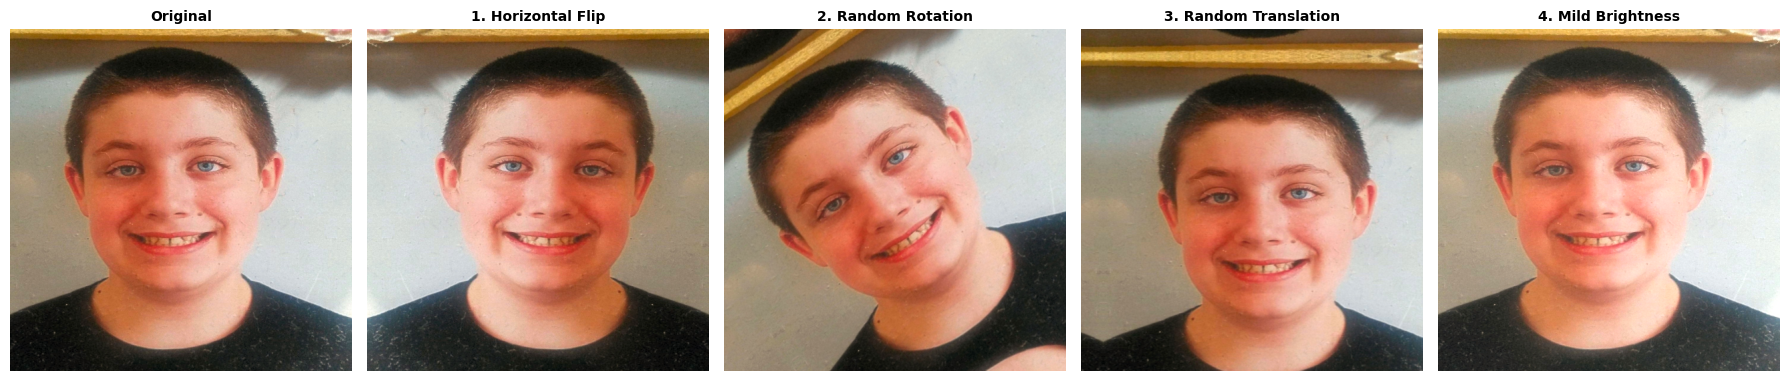

In [31]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

if 'processed_samples' not in locals() and 'class_sample_images' in locals():
    processed_samples = {}
    for class_name, img_path in class_sample_images.items():
        img_bgr = cv2.imread(img_path)
        if img_bgr is not None:
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            img_resized = cv2.resize(img_rgb, (512, 512))
            processed_samples[class_name] = img_resized.astype(np.float32) / 255.0

sample_key = list(processed_samples.keys())[0]
sample_img = processed_samples[sample_key]
img_batch = tf.expand_dims(sample_img, axis=0)

flipped_img = tf.image.flip_left_right(sample_img).numpy()

rotation_layer = tf.keras.layers.RandomRotation(factor=0.1)
translation_layer = tf.keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1)
brightness_layer = tf.keras.layers.RandomBrightness(factor=0.1, value_range=(0.0, 1.0))

rotated_img = tf.squeeze(rotation_layer(img_batch, training=True), axis=0).numpy()
translated_img = tf.squeeze(translation_layer(img_batch, training=True), axis=0).numpy()
bright_img = tf.squeeze(brightness_layer(img_batch, training=True), axis=0).numpy()

titles = [
    "Original",
    "1. Horizontal Flip",
    "2. Random Rotation",
    "3. Random Translation",
    "4. Mild Brightness"
]
images = [sample_img, flipped_img, rotated_img, translated_img, bright_img]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, img, title in zip(axes, images, titles):
    ax.imshow(np.clip(img, 0.0, 1.0))
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Image Quality Filtering

In [32]:
import os
import cv2

IMG_SIZE = (512, 512)

def check_image_quality(img_path, blur_thresh=50.0):
    img = cv2.imread(img_path)
    if img is None:
        return "Corrupted or unreadable", 0.0, False

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    lap_var = cv2.Laplacian(gray, cv2.CV_64F).var()

    status = "Passed"
    if lap_var < blur_thresh:
        status = "Blurry"

    return status, lap_var, True

for class_name, img_path in class_sample_images.items():
    status, lap_var, readable = check_image_quality(img_path)
    corruption = "None" if readable else "Yes"
    print(f"Class: {class_name} | Resolution: IMG_SIZE = {IMG_SIZE} | Corruption: {corruption} | Status: {status}")

Class: autistic | Resolution: IMG_SIZE = (512, 512) | Corruption: None | Status: Blurry
Class: non_autistic | Resolution: IMG_SIZE = (512, 512) | Corruption: None | Status: Passed


#  Missing-Value Imputation , Robust Scaling , Categorical Encoding

In [33]:
import os
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, OrdinalEncoder

csv_files = []
for root, dirs, files in os.walk(path):
    for f in files:
        if f.lower().endswith('.csv'):
            csv_files.append(os.path.join(root, f))

print("Found CSV files:", csv_files)

if csv_files:
    csv_path = csv_files[0]
    print(f"Loading CSV from: {csv_path}\n")
    df = pd.read_csv(csv_path)

    print("Dataset Shape:", df.shape)
    print("\nColumns & Data Types:")
    print(df.dtypes)

    numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

    nominal_cols = categorical_cols
    ordinal_cols = []

    print(f"\nNumerical Columns ({len(numerical_cols)}): {numerical_cols}")
    print(f"Nominal Columns ({len(nominal_cols)}): {nominal_cols}")
    print(f"Ordinal Columns ({len(ordinal_cols)}): {ordinal_cols}")

    numerical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ])

    nominal_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    ordinal_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder())
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numerical_transformer, numerical_cols),
            ('nom', nominal_transformer, nominal_cols),
            ('ord', ordinal_transformer, ordinal_cols)
        ],
        remainder='passthrough'
    )

    transformed_data = preprocessor.fit_transform(df)
    print("\nPreprocessing completed successfully!")
    print("Transformed data shape:", transformed_data.shape)
else:
    print("No CSV files found in the dataset directory.")

Found CSV files: ['/kaggle/input/autism-spectrum-disorder-multi-modal-dataset/Dataset_csv/valid.csv', '/kaggle/input/autism-spectrum-disorder-multi-modal-dataset/Dataset_csv/train.csv', '/kaggle/input/autism-spectrum-disorder-multi-modal-dataset/Dataset_csv/test.csv']
Loading CSV from: /kaggle/input/autism-spectrum-disorder-multi-modal-dataset/Dataset_csv/valid.csv

Dataset Shape: (200, 16)

Columns & Data Types:
image_path    object
A1             int64
A2             int64
A3             int64
A4             int64
A5             int64
A6             int64
A7             int64
A8             int64
A9             int64
A10            int64
Age            int64
Sex           object
Jauundice     object
Family_ASD    object
Class         object
dtype: object

Numerical Columns (11): ['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10', 'Age']
Nominal Columns (5): ['image_path', 'Sex', 'Jauundice', 'Family_ASD', 'Class']
Ordinal Columns (0): []

Preprocessing completed successfull

In [34]:
import pandas as pd

for csv_file in csv_files:
    df_temp = pd.read_csv(csv_file)
    print(f"File: {os.path.basename(csv_file)} | Shape: {df_temp.shape}")

print("\nPipeline Summary:")
print(f"• Numerical Imputation & Robust Scaling applied to: {len(numerical_cols)} columns")
print(f"• Nominal Imputation & One-Hot Encoding applied to: {len(nominal_cols)} columns (resulting in {transformed_data.shape[1]} total features)")
print("• Missing values handled successfully via median and most-frequent strategies.")

File: valid.csv | Shape: (200, 16)
File: train.csv | Shape: (2526, 16)
File: test.csv | Shape: (200, 16)

Pipeline Summary:
• Numerical Imputation & Robust Scaling applied to: 11 columns
• Nominal Imputation & One-Hot Encoding applied to: 5 columns (resulting in 219 total features)
• Missing values handled successfully via median and most-frequent strategies.


# Split Dataset

Classes: ['autistic' 'non_autistic']
Train: 2526
Validation: 200
Test: 200

Class distribution:

TRAIN
{np.str_('autistic'): np.int64(1263), np.str_('non_autistic'): np.int64(1263)}

VALID
{np.str_('autistic'): np.int64(100), np.str_('non_autistic'): np.int64(100)}

TEST
{np.str_('autistic'): np.int64(100), np.str_('non_autistic'): np.int64(100)}


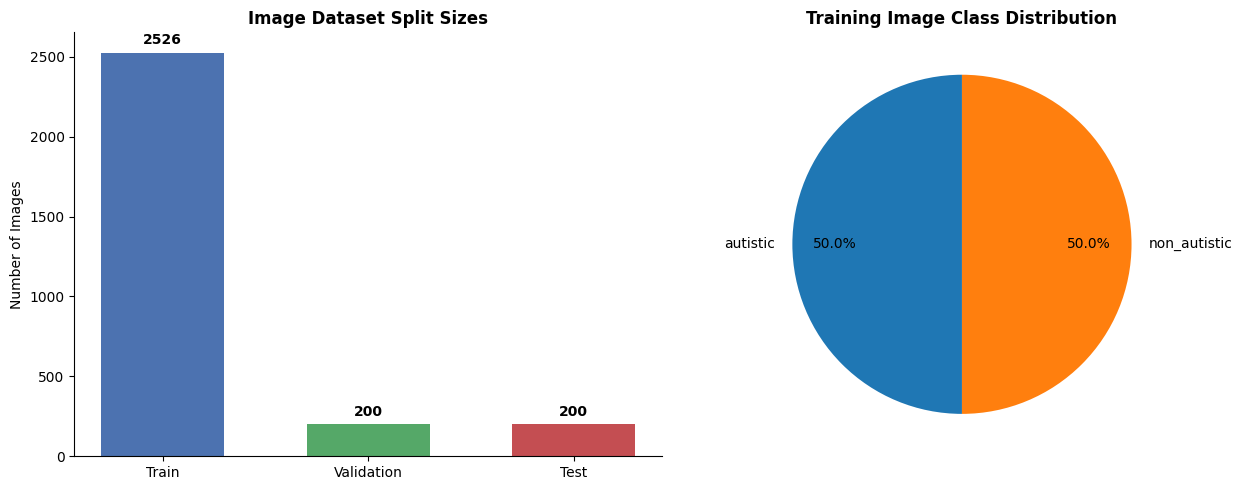

In [35]:
import os
import numpy as np
import matplotlib.pyplot as plt

image_root = os.path.join(path, "Dataset_img")
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

split_data_vars = {}
class_images = {}

# Detect existing train/valid/test folders
existing_splits = {
    name: os.path.join(image_root, name)
    for name in ["train", "valid", "test"]
    if os.path.isdir(os.path.join(image_root, name))
}

if existing_splits:
    for split_name, split_root in existing_splits.items():
        split_images = []
        split_labels = []

        for root, _, files in os.walk(split_root):
            for file in files:
                if file.lower().endswith(extensions):
                    image_path = os.path.join(root, file)
                    relative_path = os.path.relpath(image_path, split_root)
                    parts = relative_path.split(os.sep)

                    # Class is the first folder inside the split
                    class_name = parts[0] if len(parts) > 1 else os.path.basename(split_root)

                    split_images.append(image_path)
                    split_labels.append(class_name)
                    class_images.setdefault(class_name, []).append(image_path)

        split_data_vars[split_name] = {
            "images": np.asarray(split_images),
            "labels": np.asarray(split_labels)
        }

else:
    # Dataset has class folders directly under Dataset_img
    for root, _, files in os.walk(image_root):
        for file in files:
            if file.lower().endswith(extensions):
                image_path = os.path.join(root, file)
                relative_path = os.path.relpath(image_path, image_root)
                class_name = relative_path.split(os.sep)[0]
                class_images.setdefault(class_name, []).append(image_path)

    images, labels = [], []

    for class_name, paths in sorted(class_images.items()):
        images.extend(paths)
        labels.extend([class_name] * len(paths))

    images = np.asarray(images)
    labels = np.asarray(labels)

    indices = np.random.default_rng(42).permutation(len(images))
    train_end = int(0.70 * len(images))
    valid_end = int(0.85 * len(images))

    for split_name, idx in [
        ("train", indices[:train_end]),
        ("valid", indices[train_end:valid_end]),
        ("test", indices[valid_end:])
    ]:
        split_data_vars[split_name] = {
            "images": images[idx],
            "labels": labels[idx]
        }

# Assign variables
X_train_images = split_data_vars["train"]["images"]
y_train = split_data_vars["train"]["labels"]

X_valid_images = split_data_vars["valid"]["images"]
y_valid = split_data_vars["valid"]["labels"]

X_test_images = split_data_vars["test"]["images"]
y_test = split_data_vars["test"]["labels"]

print("Classes:", np.unique(y_train))
print("Train:", len(y_train))
print("Validation:", len(y_valid))
print("Test:", len(y_test))

print("\nClass distribution:")
for split_name, data in split_data_vars.items():
    print(f"\n{split_name.upper()}")
    print(dict(zip(*np.unique(data["labels"], return_counts=True))))

split_counts = {
    "Train": len(y_train),
    "Validation": len(y_valid),
    "Test": len(y_test)
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bars = axes[0].bar(
    split_counts.keys(),
    split_counts.values(),
    color=["#4C72B0", "#55A868", "#C44E52"],
    width=0.6
)
axes[0].set_title("Image Dataset Split Sizes", fontweight="bold")
axes[0].set_ylabel("Number of Images")
axes[0].bar_label(bars, fmt="%d", padding=4, fontweight="bold")
axes[0].spines[["top", "right"]].set_visible(False)

classes, counts = np.unique(y_train, return_counts=True)
axes[1].pie(
    counts,
    labels=classes,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75
)
axes[1].set_title("Training Image Class Distribution", fontweight="bold")

plt.tight_layout()
plt.show()

# Build Model

In [44]:
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers, models
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train).astype(np.float32)
y_valid_encoded = label_encoder.transform(y_valid).astype(np.float32)

if len(label_encoder.classes_) != 2:
    raise ValueError(f"Expected 2 classes, found {list(label_encoder.classes_)}")

IMG_SIZE, BATCH_SIZE = (224, 224), 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_path, label):
    image = tf.io.decode_image(
        tf.io.read_file(image_path), channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    return preprocess_input(tf.image.resize(image, IMG_SIZE)), label

def extract_proxy_features(paths):
    features = []
    for p in paths:
        image = tf.io.decode_image(
            tf.io.read_file(p), channels=3, expand_animations=False
        )
        image = tf.cast(tf.image.resize(image, (64, 64)), tf.float32) / 255.
        gray = tf.image.rgb_to_grayscale(image).numpy().squeeze()
        rgb = image.numpy()
        hist = np.concatenate([
            np.histogram(rgb[:, :, c], bins=4, range=(0, 1))[0] / 4096
            for c in range(3)
        ])
        features.append([
            gray.mean(), gray.std(),
            np.abs(np.diff(gray, axis=0)).mean(),
            np.abs(np.diff(gray, axis=1)).mean(),
            *np.percentile(gray, [10, 25, 50, 75, 90]),
            *hist[:7]
        ])
    return np.asarray(features, dtype=np.float32)

X_train_behavior = extract_proxy_features(X_train_images)
X_valid_behavior = extract_proxy_features(X_valid_images)

mean = X_train_behavior.mean(axis=0)
std = X_train_behavior.std(axis=0)
std[std < 1e-6] = 1
X_train_behavior = (X_train_behavior - mean) / std
X_valid_behavior = (X_valid_behavior - mean) / std

def augment_image(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.image.random_saturation(image, lower=0.8, upper=1.2)
    return image, label

def make_dataset(paths, behavior, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, behavior, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=42, reshuffle_each_iteration=True)

    def prepare(p, b, y):
        image, y = load_image(p, y)
        if training:
            image, y = augment_image(image, y)
        return {
            "image_input": image,
            "behavior_input": b
        }, y

    return ds.map(prepare, num_parallel_calls=AUTOTUNE).batch(
        BATCH_SIZE
    ).prefetch(AUTOTUNE)

train_ds = make_dataset(
    X_train_images, X_train_behavior, y_train_encoded, True
)
valid_ds = make_dataset(
    X_valid_images, X_valid_behavior, y_valid_encoded, False
)

class AutismScreeningSystem:
    def __init__(self, latent_dim=128, num_behavior_features=16):
        self.latent_dim = latent_dim
        self.num_behavior_features = num_behavior_features
        self.model = self._build_lcff_net()

    def _build_lcff_net(self):
        image_input = layers.Input((224, 224, 3), name="image_input")
        behavior_input = layers.Input(
            (self.num_behavior_features,), name="behavior_input"
        )

        # Lightweight Dual-Branch Feature Extraction
        backbone = tf.keras.applications.MobileNetV3Large(
            input_shape=(224, 224, 3),
            include_top=False,
            weights="imagenet",
            pooling=None
        )
        backbone.trainable = True
        for sub_layer in backbone.layers[:-50]:
            sub_layer.trainable = False

        x = backbone(image_input)
        x = layers.Conv2D(256, (3, 3), padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.DepthwiseConv2D(3, padding="same", activation="relu")(x)
        x = layers.Conv2D(256, (1, 1), padding="same", activation="relu")(x)
        channels = x.shape[-1]
        se = layers.GlobalAveragePooling2D()(x)
        se = layers.Dense(max(channels // 8, 16), activation="relu")(se)
        se = layers.Dense(channels, activation="sigmoid")(se)
        se = layers.Reshape((1, 1, channels))(se)
        x = layers.Multiply()([x, se])
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dropout(0.4)(x)
        visual_embedding = layers.Dense(
            self.latent_dim, activation="relu", name="visual_embedding"
        )(x)

        b = layers.Dense(128)(behavior_input)
        b = layers.BatchNormalization()(b)
        b = layers.Activation("relu")(b)
        residual = layers.Dense(128)(b)
        b = layers.Add()([b, residual])
        b = layers.LayerNormalization()(b)
        gate = layers.Dense(128, activation="sigmoid")(b)
        b = layers.Multiply()([b, gate])
        b = layers.Dropout(0.3)(b)
        behavior_embedding = layers.Dense(
            self.latent_dim, activation="relu", name="behavior_embedding"
        )(b)

        # Lightweight Cross-Modal Feature Fusion Network (LCFF-Net)
        v_proj = layers.Dense(self.latent_dim)(visual_embedding)
        b_proj = layers.Dense(self.latent_dim)(behavior_embedding)
        v_seq = layers.Reshape((1, self.latent_dim))(v_proj)
        b_seq = layers.Reshape((1, self.latent_dim))(b_proj)

        attn = layers.MultiHeadAttention(
            num_heads=4, key_dim=self.latent_dim // 4
        )(query=v_seq, value=b_seq, key=b_seq)
        attn = layers.Flatten()(attn)

        v_drop = layers.Dropout(0.15)(v_proj)
        b_drop = layers.Dropout(0.15)(b_proj)

        combined = layers.Concatenate()([v_drop, b_drop, attn])
        fusion_gate = layers.Dense(
            self.latent_dim * 2, activation="sigmoid"
        )(combined)
        gated = layers.Multiply()([
            layers.Concatenate()([v_drop, b_drop]), fusion_gate
        ])
        fused = layers.Dense(self.latent_dim, activation="relu")(gated)
        fused = layers.Add()([fused, v_proj])
        fused = layers.Dropout(0.3)(fused)
        fused_pred = layers.Dense(
            1, activation="sigmoid", name="fused_pred"
        )(fused)

        model = models.Model(
            inputs=[image_input, behavior_input],
            outputs=fused_pred,
            name="LCFF_Net_Binary_Classification"
        )

        model.compile(
            optimizer=tf.keras.optimizers.Adam(1e-5),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )
        return model

    # Robust Intuitionistic Fuzzy Evidence Aggregation (RIFEA)
    def compute_rifea_evidence(self, p_vis, p_beh, p_fused, weights=(0.3, 0.3, 0.4)):
        preds = np.clip(
            np.array([p_vis, p_beh, p_fused], dtype=float), 1e-7, 1 - 1e-7
        )
        w = np.asarray(weights, dtype=float)
        w /= w.sum()

        mu = float(np.sum(w * preds))
        nu = float(np.sum(w * (1 - preds)))
        hesitation = max(0.0, 1.0 - mu - nu)
        conflict = float(abs(p_vis - p_beh))

        entropy = -(preds * np.log(preds) + (1 - preds) * np.log(1 - preds))
        criterion_weights = (1 / (entropy + 1e-8))
        criterion_weights /= criterion_weights.sum()
        entropy_score = float(np.sum(criterion_weights * preds))

        return {
            "aggregate_score": mu,
            "membership": mu,
            "non_membership": nu,
            "hesitation": hesitation,
            "modality_conflict": conflict,
            "entropy_weighted_score": entropy_score
        }

    # Robust Comparative Screening and Decision Ranking (RCSR)
    def rcsr_decision_ranking(self, evidence, threshold=0.5, conflict_threshold=0.4, hesitation_threshold=0.3):
        score = evidence["aggregate_score"]
        uncertainty = (
            evidence["modality_conflict"] > conflict_threshold
            or evidence["hesitation"] > hesitation_threshold
            or abs(score - threshold) < 0.05
        )
        return {
            "topsis_score": float(score),
            "uncertainty_flag": bool(uncertainty),
            "final_decision": (
                "Refer for Professional Assessment" if uncertainty
                else "Positive Screening" if score >= threshold
                else "Negative Screening"
            )
        }

system = AutismScreeningSystem()
model = system.model
model.summary()

Model: "LCFF_Net_Binary_Classification"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 image_input (InputLayer)    [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 MobilenetV3large (Function  (None, 7, 7, 960)            2996352   ['image_input[0][0]']         
 al)                                                                                              
                                                                                                  
 conv2d_4 (Conv2D)           (None, 7, 7, 256)            2212096   ['MobilenetV3large[0][0]']    
                                                                                                  
 batch_normalization_12 (Ba  (None, 7, 7, 256)            1024      [

# Train model

In [ ]:

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=50,
    callbacks=callbacks,
    verbose=1
)

train_loss = history.history['loss']
val_loss = history.history['val_loss']
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

Epoch 1/50
79/79 [==============================] - 21s 99ms/step - loss: 0.6973 - accuracy: 0.5036 - val_loss: 0.7170 - val_accuracy: 0.3333 - lr: 1.0000e-05
Epoch 2/50
79/79 [==============================] - 7s 84ms/step - loss: 0.6871 - accuracy: 0.5519 - val_loss: 0.6879 - val_accuracy: 0.6667 - lr: 1.0000e-05
Epoch 3/50
79/79 [==============================] - 7s 84ms/step - loss: 0.6734 - accuracy: 0.5891 - val_loss: 0.6618 - val_accuracy: 0.6667 - lr: 1.0000e-05
Epoch 4/50
79/79 [==============================] - 7s 84ms/step - loss: 0.6534 - accuracy: 0.6362 - val_loss: 0.6337 - val_accuracy: 0.7333 - lr: 1.0000e-05
Epoch 5/50
79/79 [==============================] - 7s 84ms/step - loss: 0.6287 - accuracy: 0.6880 - val_loss: 0.6033 - val_accuracy: 0.7333 - lr: 1.0000e-05
Epoch 6/50
79/79 [==============================] - 7s 85ms/step - loss: 0.5962 - accuracy: 0.7237 - val_loss: 0.5737 - val_accuracy: 0.7333 - lr: 1.0000e-05
Epoch 7/50
79/79 [==============================] -